In [1]:
from google.colab import files  # Imports the file-upload utility for Google Colab
uploaded = files.upload()  # Opens a dialog to upload Mall_Customers.csv

Saving Mall_Customers.csv to Mall_Customers.csv


In [2]:
import pandas as pd  # Imports pandas for handling the customer dataset
import numpy as np  # Imports NumPy for numerical calculations
import matplotlib.pyplot as plt  # Imports Matplotlib for visualizing clusters

from sklearn.model_selection import train_test_split  # Imports the function to split training and testing data
from sklearn.preprocessing import StandardScaler  # Imports scaling to normalize feature ranges
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN  # Imports three clustering algorithms
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score  # Imports clustering evaluation metrics
from sklearn.neighbors import NearestNeighbors  # Imports nearest-neighbor search for DBSCAN test assignment

In [3]:
df = pd.read_csv("Mall_Customers.csv")  # Reads the uploaded CSV file into a DataFrame
print("Dataset shape:", df.shape)  # Displays the number of rows and columns
print(df.head())  # Displays the first five customer records
print(df.isnull().sum())  # Checks the number of missing values in each column

Dataset shape: (200, 5)
   CustomerID   Genre  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40
CustomerID                0
Genre                     0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


In [4]:
X = df[["Annual Income (k$)", "Spending Score (1-100)"]]  # Selects annual income and spending score for clustering

X_train, X_test = train_test_split(  # Splits the selected features into training and testing sets
    X, test_size=0.20, random_state=42  # Uses 80% for training and 20% for testing
)  # Completes the split reproducibly

scaler = StandardScaler()  # Creates a scaler to give both features comparable scales
X_train_scaled = scaler.fit_transform(X_train)  # Learns scaling parameters from training data and transforms it
X_test_scaled = scaler.transform(X_test)  # Applies the same training scaling parameters to test data

print("Training records:", len(X_train))  # Displays the number of training records
print("Testing records:", len(X_test))  # Displays the number of testing records

Training records: 160
Testing records: 40


In [5]:
models = {  # Creates a dictionary to store all three clustering algorithms

    "K-Means": KMeans(  # Creates the K-Means clustering model
        n_clusters=5,  # Requests five customer clusters
        random_state=42,  # Makes initialization reproducible
        n_init=10  # Runs ten initializations and retains the best solution
    ),  # Finishes the K-Means model

    "Agglomerative": AgglomerativeClustering(  # Creates the hierarchical clustering model
        n_clusters=5,  # Requests five customer clusters
        linkage="ward"  # Merges groups using Ward's variance-minimization method
    ),  # Finishes the Agglomerative model

    "DBSCAN": DBSCAN(  # Creates the density-based clustering model
        eps=0.30,  # Sets the maximum neighborhood distance in scaled feature space
        min_samples=5  # Requires at least five nearby points for a core point
    )  # Finishes the DBSCAN model

}  # Finishes the dictionary of clustering algorithms

In [6]:
results = []  # Creates a list to store evaluation results
train_labels = {}  # Stores the cluster labels assigned to training records
test_labels = {}  # Stores the cluster assignments for testing records

for name, model in models.items():  # Iterates over the three clustering algorithms

    model.fit(X_train_scaled)  # Learns clusters from the training data
    labels_train = model.labels_  # Retrieves the training cluster labels

    if name == "K-Means":  # Checks whether the current algorithm is K-Means
        labels_test = model.predict(X_test_scaled)  # Assigns test records to the nearest learned cluster center

    elif name == "Agglomerative":  # Checks whether the current algorithm is Agglomerative
        centers = np.vstack([  # Calculates one representative center for each training cluster
            X_train_scaled[labels_train == label].mean(axis=0)  # Computes the mean of each cluster's training points
            for label in np.unique(labels_train)  # Iterates through the cluster labels found during training
        ])  # Finishes building the cluster-center array

        unique_labels = np.unique(labels_train)  # Retrieves the original training cluster labels
        distances = np.linalg.norm(  # Calculates the distance from each test record to every cluster center
            X_test_scaled[:, None, :] - centers[None, :, :], axis=2  # Broadcasts test records against cluster centers
        )  # Finishes the distance calculation

        labels_test = unique_labels[np.argmin(distances, axis=1)]  # Assigns each test record to its nearest cluster center

    else:  # Handles the DBSCAN algorithm
        core_points = model.components_  # Retrieves DBSCAN's core training samples
        core_labels = labels_train[model.core_sample_indices_]  # Retrieves the cluster label of each core sample

        if len(core_points) == 0:  # Checks whether DBSCAN found any core points
            labels_test = np.full(len(X_test_scaled), -1)  # Marks all test records as noise if no core points exist
        else:  # Runs when DBSCAN has at least one core point
            neighbors = NearestNeighbors(n_neighbors=1)  # Creates a nearest-neighbor model
            neighbors.fit(core_points)  # Indexes the DBSCAN core points
            distances, indices = neighbors.kneighbors(X_test_scaled)  # Finds the nearest core point for each test record
            labels_test = core_labels[indices[:, 0]].copy()  # Initially assigns the nearest core point's cluster
            labels_test[distances[:, 0] > model.eps] = -1  # Marks records outside eps distance as noise

    train_labels[name] = labels_train  # Saves the training cluster assignments
    test_labels[name] = labels_test  # Saves the testing cluster assignments

    valid_train = labels_train != -1 if name == "DBSCAN" else np.ones(len(labels_train), dtype=bool)  # Excludes DBSCAN noise from cluster-quality scores
    valid_test = labels_test != -1 if name == "DBSCAN" else np.ones(len(labels_test), dtype=bool)  # Excludes test noise from cluster-quality scores

    train_X_valid = X_train_scaled[valid_train]  # Selects training points included in evaluation
    train_y_valid = labels_train[valid_train]  # Selects their cluster labels
    test_X_valid = X_test_scaled[valid_test]  # Selects test points included in evaluation
    test_y_valid = labels_test[valid_test]  # Selects their cluster labels

    def calculate_scores(data, labels):  # Defines a helper function to calculate clustering scores
        cluster_count = len(np.unique(labels))  # Counts the distinct clusters in the evaluated data

        if cluster_count < 2 or cluster_count >= len(labels):  # Checks whether the scores can be calculated meaningfully
            return np.nan, np.nan, np.nan  # Returns unavailable scores when there are too few or too many clusters

        sil = silhouette_score(data, labels)  # Calculates the Silhouette Score; higher is better
        dbi = davies_bouldin_score(data, labels)  # Calculates the Davies-Bouldin Index; lower is better
        chi = calinski_harabasz_score(data, labels)  # Calculates the Calinski-Harabasz Score; higher is better

        return sil, dbi, chi  # Returns the three clustering evaluation metrics

    train_sil, train_dbi, train_chi = calculate_scores(train_X_valid, train_y_valid)  # Evaluates the training clusters
    test_sil, test_dbi, test_chi = calculate_scores(test_X_valid, test_y_valid)  # Evaluates assigned test clusters

    results.append({  # Stores the evaluation results for the current algorithm
        "Algorithm": name,  # Records the algorithm name
        "Train Silhouette": train_sil,  # Records training cluster separation and cohesion
        "Test Silhouette": test_sil,  # Records test cluster separation and cohesion
        "Test Davies-Bouldin": test_dbi,  # Records test cluster overlap-related score
        "Test Calinski-Harabasz": test_chi,  # Records test cluster separation score
        "Test Noise %": np.mean(labels_test == -1) * 100 if name == "DBSCAN" else 0.0  # Records the percentage of test records marked as noise
    })  # Finishes storing this algorithm's results

    print(f"{name} training and testing completed")  # Confirms the current algorithm has been evaluated
    print("Training clusters:", len(set(labels_train) - {-1}))  # Displays the number of non-noise training clusters
    print("Testing clusters:", len(set(labels_test) - {-1}))  # Displays the number of non-noise test clusters
    print(f"Test Silhouette Score: {test_sil:.4f}")  # Displays the test silhouette score

K-Means training and testing completed
Training clusters: 5
Testing clusters: 5
Test Silhouette Score: 0.5668
Agglomerative training and testing completed
Training clusters: 5
Testing clusters: 5
Test Silhouette Score: 0.5478
DBSCAN training and testing completed
Training clusters: 5
Testing clusters: 4
Test Silhouette Score: 0.5665


In [7]:
results_df = pd.DataFrame(results)  # Converts the stored results into a comparison table
display(results_df.round(4))  # Displays all clustering evaluation scores to four decimal places

print("\nComparison completed for all three algorithms.")  # Prints a completion message

,Algorithm,Train Silhouette,Test Silhouette,Test Davies-Bouldin,Test Calinski-Harabasz,Test Noise %
0,K-Means,0.5530,0.5668,0.5249,58.3464,0.0
1,Agglomerative,0.5534,0.5478,0.5480,53.8933,0.0
2,DBSCAN,0.6147,0.5665,0.4340,35.5263,27.5



Comparison completed for all three algorithms.


In [8]:
valid_results = results_df.dropna(subset=["Test Silhouette"]).copy()  # Keeps models with a valid test Silhouette Score

if valid_results.empty:  # Checks whether any model has a valid Silhouette Score
    print("No valid test scores. Adjust DBSCAN parameters and rerun.")  # Explains what to do if no model can be ranked
else:  # Continues when at least one model has a valid score
    best_row = valid_results.loc[valid_results["Test Silhouette"].idxmax()]  # Selects the model with the highest test Silhouette Score

    print("BEST CLUSTERING ALGORITHM:", best_row["Algorithm"])  # Displays the highest-ranked algorithm
    print(f"Test Silhouette Score: {best_row['Test Silhouette']:.4f}")  # Displays its test Silhouette Score
    print(f"Test Davies-Bouldin Index: {best_row['Test Davies-Bouldin']:.4f}")  # Displays its Davies-Bouldin Index
    print(f"Test Calinski-Harabasz Score: {best_row['Test Calinski-Harabasz']:.4f}")  # Displays its Calinski-Harabasz Score

BEST CLUSTERING ALGORITHM: K-Means
Test Silhouette Score: 0.5668
Test Davies-Bouldin Index: 0.5249
Test Calinski-Harabasz Score: 58.3464


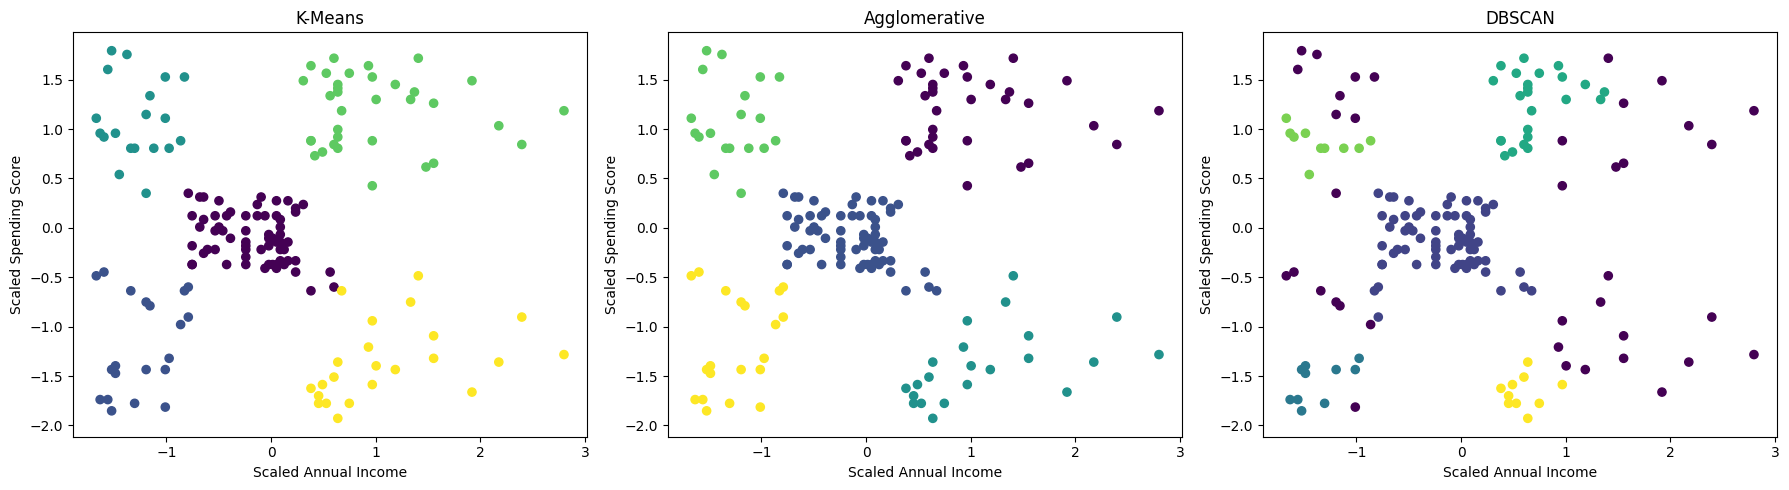

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))  # Creates three plots in one row for algorithm comparison

for ax, name in zip(axes, models.keys()):  # Pairs each plot with one clustering algorithm
    labels = train_labels[name]  # Retrieves the training cluster labels
    ax.scatter(  # Draws customers as points
        X_train_scaled[:, 0],  # Uses scaled annual income on the horizontal axis
        X_train_scaled[:, 1],  # Uses scaled spending score on the vertical axis
        c=labels,  # Colors points according to their assigned clusters
        cmap="viridis",  # Applies a color map to distinguish clusters
        s=35  # Sets the marker size
    )  # Finishes the scatter plot
    ax.set_title(name)  # Adds the algorithm name as the plot title
    ax.set_xlabel("Scaled Annual Income")  # Labels the horizontal axis
    ax.set_ylabel("Scaled Spending Score")  # Labels the vertical axis

plt.tight_layout()  # Adjusts spacing between the plots
plt.show()  # Displays the three cluster visualizations

**Title: Comparison of Three Clustering Algorithms Using Mall Customers Dataset**

**Objective:** To apply K-Means, Agglomerative Clustering, and DBSCAN to customer data and compare their clustering performance.

**Procedure:** The dataset was loaded into Google Colab, and annual income and spending score were selected as features. The data was standardized and divided into 80% training and 20% testing sets. Each algorithm was fitted on the training data and evaluated using Silhouette Score, Davies–Bouldin Index, and Calinski–Harabasz Score.

**Result:** The three clustering algorithms were compared using the calculated evaluation metrics. The algorithm with the highest valid test Silhouette Score was selected as the best-performing model for this experiment.

**Conclusion:** Clustering helps identify customer groups based on their income and spending behavior. These groups can support customer segmentation and targeted marketing strategies. The final best algorithm is determined by the actual scores obtained in Google Colab.